In [1]:
import sys
from pathlib import Path
if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
DATA_DIR = Path('/content/drive/MyDrive/DeepMinds')   # shared folder: holds project_utils.py + torch_models.py
sys.path.append(str(DATA_DIR))
FIG_DIR = DATA_DIR / 'figures'; FIG_DIR.mkdir(exist_ok=True)
LOG = DATA_DIR / 'results_log.csv'

Mounted at /content/drive


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from project_utils import URL_FEATURES, load_master, get_feature_splits, evaluate_model, log_result

df = load_master(DATA_DIR)
data, _ = get_feature_splits(df, URL_FEATURES, split_col='split')
X_train, y_train = data['train']
X_val, y_val = data['val']

        Model Split  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC  False positives  False negatives
Random Forest   val    0.9998        1.0  0.9996 0.9998   0.9999  0.9999                0                6


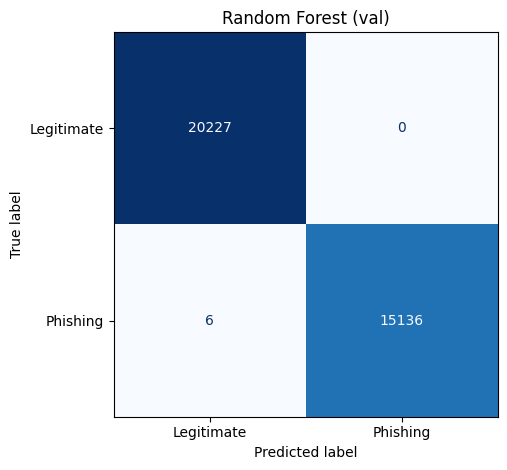

In [3]:
params = dict(n_estimators=100, max_depth=None, min_samples_leaf=1)
rf = RandomForestClassifier(**params, random_state=42, n_jobs=-1).fit(X_train, y_train)
res = evaluate_model('Random Forest', 'val', y_val, rf.predict_proba(X_val)[:, 1],
                     save_path=FIG_DIR / 'cm_rf_url_val.png')
log_result(res, {'family': 'RF', 'experiment': 'main', 'features': 'url22', 'split_col': 'split', **params}, LOG)



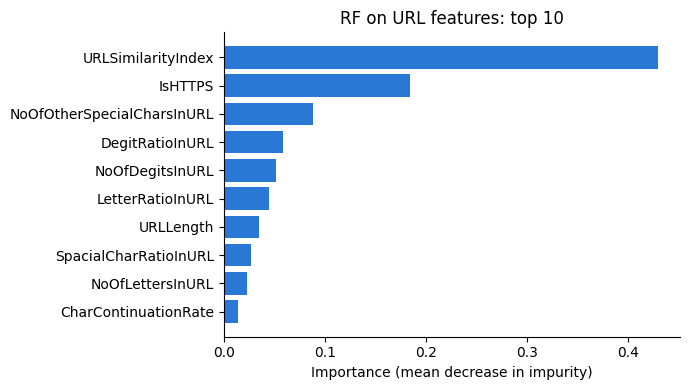

In [4]:
imp = pd.Series(rf.feature_importances_, index=URL_FEATURES).sort_values().tail(10)
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(imp.index, imp.values, color='#2a78d6')
ax.set_xlabel('Importance (mean decrease in impurity)'); ax.set_title('RF on URL features: top 10')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout(); fig.savefig(FIG_DIR / 'rf_url_importance.png', dpi=200); plt.show()